# Wilson 2025 as a neuralset Study

`Wilson2025CursorRecalibration` adapts the release into standardized events. One timeline is one task block, not one recording day: a day holds several blocks whose task and online decoder differ, and a timeline needs invariant task entities.

Each timeline emits four or five whole-block continuous streams plus two rows per trial. This notebook builds the Study on a handful of timelines and reads every event family back through its extractor.

In [1]:
import matplotlib.pyplot as plt
import neuralset as ns
import numpy as np
import pandas as pd

from neuralshed.datasets.utils import dataset_dir
from neuralshed.datasets.wilson_2025.study import Wilson2025CursorRecalibration
from neuralshed.extractors import BehavioralSeriesExtractor, NeuralFeatureExtractor

## Building the Study

The query picks four timelines that between them cover every emission path: one radial-8 `cursor` block, one `keyboard` grid block, one click-enabled block, and one `fitts` block. This is the same query the Study's `_info` guard records.

In [2]:
study = Wilson2025CursorRecalibration(
    path=str(dataset_dir("wilson_2025") / "data"),
    query="timeline_index in [0, 8, 27, 123]",
)
events = study.run()

print(f"timelines in the full study: {study._info.num_timelines}")
print(f"events in this query: {len(events)} across {events.timeline.nunique()} timelines")
print(f"subject: {events.subject.unique()}")

timelines in the full study: 560
events in this query: 730 across 4 timelines
subject: ['Wilson2025CursorRecalibration/T5']


## The standardized events table

`type`, `start` and `duration` are the required columns. Everything else rides along, either broadcast from the timeline dict (the block's task, date and curation flags) or attached per row.

In [3]:
print(events.type.value_counts().to_string())
print()
print("columns:", sorted(events.columns))

type
Stimulus                356
Action                  356
SpikeCounts               4
CursorPositionSeries      4
TargetPositionSeries      4
DecodedCursorVelocitySeries      4
ClickStateSeries          2

columns: ['action_kind', 'analysis_block', 'block', 'click_enabled', 'code', 'date', 'description', 'dims', 'duration', 'feature', 'filepath', 'frequency', 'kind', 'method', 'modality', 'n_targets', 'original_split', 'post_implant_day', 'reference_frame', 'run', 'session', 'start', 'stimulus_kind', 'stop', 'study', 'subject', 'success', 'target_size', 'target_x', 'target_y', 'task', 'task_condition', 'threshold', 'timeline', 'trial_id', 'type', 'unit']


In [4]:
columns = ["type", "start", "duration", "task", "code", "trial_id", "success", "feature"]
one = events[events.timeline == events.timeline.iloc[0]]
one[columns].head(10)

,type,start,duration,task,code,trial_id,success,feature
0,SpikeCounts,0.00,169.64,cursor,NaN,NaN,NaN,threshold_crossings
1,CursorPositionSeries,0.00,169.64,cursor,NaN,NaN,NaN,cursor_position
2,TargetPositionSeries,0.00,169.64,cursor,NaN,NaN,NaN,target_position
3,DecodedCursorVelocitySeries,0.00,169.64,cursor,NaN,NaN,NaN,decoded_velocity
4,Stimulus,0.02,2.30,cursor,5.0,0.0,NaN,NaN
5,Action,0.02,2.30,cursor,5.0,0.0,True,NaN
6,Stimulus,2.32,1.54,cursor,4.0,1.0,NaN,NaN
7,Action,2.32,1.54,cursor,4.0,1.0,True,NaN
8,Stimulus,3.86,1.38,cursor,7.0,2.0,NaN,NaN
9,Action,3.86,1.38,cursor,7.0,2.0,True,NaN


## Timeline-level attributes

Every key in the timeline dict is broadcast to all of that block's rows, which is what makes them usable as filters at training time. `original_split` is the release folder, `analysis_block` is the authors' own block curation, and `post_implant_day` is what any drift analysis needs.

In [5]:
attributes = [
    "session",
    "run",
    "task",
    "original_split",
    "date",
    "post_implant_day",
    "analysis_block",
    "click_enabled",
]
events.groupby("timeline")[attributes].first()

,session,run,task,original_split,date,post_implant_day,analysis_block,click_enabled
timeline,,,,,,,,
"Wilson2025CursorRecalibration:analysis_block=True,block=7,click_enabled=False,date=2016-09-26,original_split=historical,post_implant_day=40,run=block07,session=t5.2016.09.26,subject=T5,task=cursor",t5.2016.09.26,block07,cursor,historical,2016-09-26,40,True,False
"Wilson2025CursorRecalibration:analysis_block=True,block=7,click_enabled=False,date=2016-09-28,original_split=historical,post_implant_day=42,run=block07,session=t5.2016.09.28,subject=T5,task=keyboard",t5.2016.09.28,block07,keyboard,historical,2016-09-28,42,True,False
"Wilson2025CursorRecalibration:analysis_block=True,block=7,click_enabled=True,date=2016-10-31,original_split=historical,post_implant_day=75,run=block07,session=t5.2016.10.31,subject=T5,task=fitts",t5.2016.10.31,block07,fitts,historical,2016-10-31,75,True,True
"Wilson2025CursorRecalibration:analysis_block=True,block=8,click_enabled=True,date=2016-10-05,original_split=historical,post_implant_day=49,run=block08,session=t5.2016.10.05,subject=T5,task=cursor",t5.2016.10.05,block08,cursor,historical,2016-10-05,49,True,True


Only the click-enabled block carries a `ClickStateSeries` row, so the emitted stream set is not identical across timelines.

In [6]:
pd.crosstab(events.timeline, events.type)

type,Action,ClickStateSeries,CursorPositionSeries,DecodedCursorVelocitySeries,SpikeCounts,Stimulus,TargetPositionSeries
timeline,,,,,,,
"Wilson2025CursorRecalibration:analysis_block=True,block=7,click_enabled=False,date=2016-09-26,original_split=historical,post_implant_day=40,run=block07,session=t5.2016.09.26,subject=T5,task=cursor",95,0,1,1,1,95,1
"Wilson2025CursorRecalibration:analysis_block=True,block=7,click_enabled=False,date=2016-09-28,original_split=historical,post_implant_day=42,run=block07,session=t5.2016.09.28,subject=T5,task=keyboard",26,0,1,1,1,26,1
"Wilson2025CursorRecalibration:analysis_block=True,block=7,click_enabled=True,date=2016-10-31,original_split=historical,post_implant_day=75,run=block07,session=t5.2016.10.31,subject=T5,task=fitts",110,1,1,1,1,110,1
"Wilson2025CursorRecalibration:analysis_block=True,block=8,click_enabled=True,date=2016-10-05,original_split=historical,post_implant_day=49,run=block08,session=t5.2016.10.05,subject=T5,task=cursor",125,1,1,1,1,125,1


## Reading the continuous streams

The four always-present streams are read through their extractors. Everything is dims-first `(n_rows, T)` and shares the block's 50 Hz time base, so the neural and behavioral arrays line up sample for sample.

In [7]:
segmenter = ns.dataloader.Segmenter(
    extractors={
        "neural": NeuralFeatureExtractor(target_unit="native", frequency=50, event_types="SpikeCounts"),
        "cursor": BehavioralSeriesExtractor(frequency=50, event_types="CursorPositionSeries"),
        "target": BehavioralSeriesExtractor(frequency=50, event_types="TargetPositionSeries"),
        "decoded_velocity": BehavioralSeriesExtractor(
            frequency=50, event_types="DecodedCursorVelocitySeries"
        ),
    },
    trigger_query="type == 'Action' and action_kind == 'cursor_control'",
    duration=None,
)
segments = segmenter.apply(events)
segments.prepare()
segments.pad_duration = "auto"

print(f"one segment per trial: {len(segments)}")
print({key: tuple(value.shape) for key, value in segments[0].data.items()})

2026-08-13 12:30:10 - INFO - neuralset.dataloader:222 - Preparing extractor: NeuralFeatureExtractor


  0%|          | 0/4 [00:00<?, ?it/s]

 75%|███████▌  | 3/4 [00:00<00:00, 22.35it/s]

100%|██████████| 4/4 [00:00<00:00, 22.24it/s]


2026-08-13 12:30:11 - INFO - neuralset.dataloader:222 - Preparing extractor: BehavioralSeriesExtractor


...


2026-08-13 12:30:11 - INFO - neuralset.dataloader:222 - Preparing extractor: BehavioralSeriesExtractor


  0%|          | 0/4 [00:00<?, ?it/s]

 50%|█████     | 2/4 [00:00<00:00, 16.31it/s]

100%|██████████| 4/4 [00:00<00:00, 18.02it/s]

one segment per trial: 356
{'neural': (1, 192, 751), 'cursor': (1, 2, 751), 'target': (1, 2, 751), 'decoded_velocity': (1, 2, 751)}


The fifth stream, the online click decoder's output, exists only on click-enabled blocks and is read separately.

In [8]:
click_timeline = events[events.type == "ClickStateSeries"].timeline.iloc[0]
click_events = events[events.timeline == click_timeline]

click_segmenter = ns.dataloader.Segmenter(
    extractors={
        "click": BehavioralSeriesExtractor(frequency=50, event_types="ClickStateSeries")
    },
    trigger_query="type == 'Action'",
    duration=None,
)
click_segments = click_segmenter.apply(click_events)
click_segments.prepare()
click_segments.pad_duration = "auto"

print(f"timeline {click_timeline}")
print(f"click segments: {len(click_segments)}")
print({key: tuple(value.shape) for key, value in click_segments[0].data.items()})

2026-08-13 12:30:11 - INFO - neuralset.dataloader:222 - Preparing extractor: BehavioralSeriesExtractor


timeline Wilson2025CursorRecalibration:analysis_block=True,block=8,click_enabled=True,date=2016-10-05,original_split=historical,post_implant_day=49,run=block08,session=t5.2016.10.05,subject=T5,task=cursor
click segments: 125
{'click': (1, 1, 127)}


## Checking the streams against each other

A useful sanity check on the alignment: within a trial the cursor should travel towards its target, so the distance from cursor to target should fall. Reading a whole block's streams and overlaying the trial boundaries shows the task structure directly.

In [9]:
block_segmenter = ns.dataloader.Segmenter(
    extractors={
        "neural": NeuralFeatureExtractor(target_unit="native", frequency=50, event_types="SpikeCounts"),
        "cursor": BehavioralSeriesExtractor(frequency=50, event_types="CursorPositionSeries"),
        "target": BehavioralSeriesExtractor(frequency=50, event_types="TargetPositionSeries"),
    },
    trigger_query="type == 'SpikeCounts'",
    duration=None,
)
whole = block_segmenter.apply(events[events.timeline == events.timeline.iloc[0]])
whole.prepare()
whole.pad_duration = "auto"
block = whole[0].data

neural = np.asarray(block["neural"])[0]
cursor = np.asarray(block["cursor"])[0]
target = np.asarray(block["target"])[0]
print("neural", neural.shape, "| cursor", cursor.shape, "| target", target.shape)

2026-08-13 12:30:11 - INFO - neuralset.dataloader:222 - Preparing extractor: NeuralFeatureExtractor


2026-08-13 12:30:11 - INFO - neuralset.dataloader:222 - Preparing extractor: BehavioralSeriesExtractor


2026-08-13 12:30:11 - INFO - neuralset.dataloader:222 - Preparing extractor: BehavioralSeriesExtractor


neural (192, 8482) | cursor (2, 8482) | target (2, 8482)


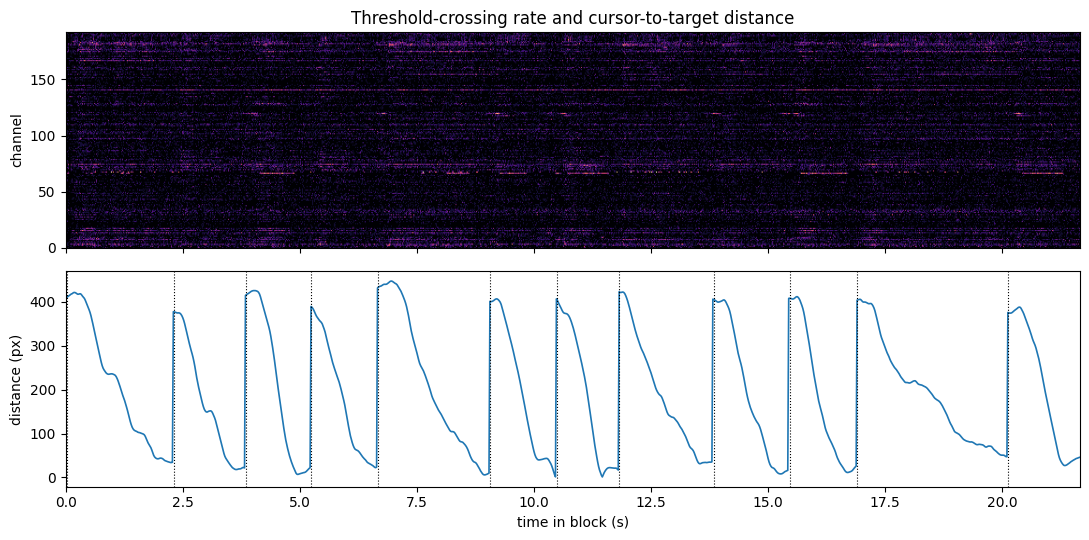

In [10]:
distance = np.linalg.norm(target - cursor, axis=0)
trials = one[one.type == "Action"].head(12)
window = slice(0, int(trials.iloc[-1].stop * 50))
time = np.arange(len(distance))[window] / 50

fig, axes = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True)
axes[0].imshow(
    neural[:, window],
    aspect="auto",
    origin="lower",
    extent=[time[0], time[-1], 0, neural.shape[0]],
    cmap="magma",
)
axes[0].set_ylabel("channel")
axes[0].set_title("Threshold-crossing rate and cursor-to-target distance")

axes[1].plot(time, distance[window], lw=1.2, color="tab:blue")
for _, trial in trials.iterrows():
    axes[1].axvline(trial.start, color="k", ls=":", lw=0.8)
axes[1].set_xlabel("time in block (s)")
axes[1].set_ylabel("distance (px)")
fig.tight_layout()

Each dotted line is a new target. The distance sawtooth confirms the trial rows are aligned to the behavioral streams: distance jumps when a target appears and decays as the cursor is driven onto it.

Quantifying the same thing across all trials in the query is a stronger check than one plot.

In [11]:
starts, ends = [], []
for segment in segments:
    cur = np.asarray(segment.data["cursor"])[0]
    tgt = np.asarray(segment.data["target"])[0]
    d = np.linalg.norm(tgt - cur, axis=0)
    valid = d[~np.isnan(d)]
    if valid.size > 4:
        starts.append(valid[0])
        ends.append(valid[-1])

starts, ends = np.array(starts), np.array(ends)
print(f"trials checked: {len(starts)}")
print(f"median distance at trial start: {np.median(starts):.0f} px")
print(f"median distance at trial end:   {np.median(ends):.0f} px")
print(f"trials ending closer than they started: {(ends < starts).mean():.1%}")

trials checked: 356
median distance at trial start: 409 px
median distance at trial end:   0 px
trials ending closer than they started: 99.2%


## Filtering by attribute

Selection is by type name in extractors, so anything else has to be an attribute. The columns the Study emits are chosen so the slices a model might want are all reachable: hold out whole sessions by `session` or `post_implant_day`, keep the paper's cohort with `analysis_block`, train per task, or drop failed trials with `success`.

In [12]:
actions = events[events.type == "Action"]
# Broadcast timeline attributes arrive as object dtype, so cast before reducing.
analysis = actions.analysis_block.astype(bool)
success = actions.success.astype(bool)

print("trials per task:")
print(actions.groupby("task").size().to_string())
print(f"\nsuccess rate: {success.mean():.2%}")
print(f"trials in analysis blocks: {analysis.sum()} of {len(actions)}")

successful_grid = events.query("type == 'Action' and task == 'keyboard' and success")
print(f"\nsuccessful grid trials: {len(successful_grid)}")

trials per task:
task
cursor      220
fitts       110
keyboard     26

success rate: 97.75%
trials in analysis blocks: 356 of 356

successful grid trials: 25
